## Imports

In [ ]:
!git clone https://github.com/twrauber/CSTRSIM.git

Cloning into 'CSTRSIM'...
remote: Enumerating objects: 299, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 299 (delta 2), reused 1 (delta 1), pack-reused 294 (from 3)
Receiving objects: 100% (299/299), 54.81 MiB | 23.27 MiB/s, done.
Resolving deltas: 100% (139/139), done.
Updating files: 100% (234/234), done.


In [ ]:
!pip install fortranformat

In [ ]:
import os
os.chdir('/content/CSTRSIM/python')

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                              classification_report, accuracy_score,
                              f1_score, recall_score, precision_score)

from CSTR import CSTR, Fault
from CSTR_plot import read_X, dataframe2sklearn

## **Visão geral do simulador CSTR**

O simulador modela a dinâmica de um reator químico contínuo (CSTR) operando em malha fechada com controladores, sensores e restrições físicas.

O sistema permite simular:

* operação normal;
* falhas de processo, que alteram parâmetros físicos da planta;
* falhas de sensores, que afetam as medições;
* evolução temporal das variáveis medidas;
* condições de shutdown por violação de limites de segurança.

Como saída, o simulador gera arquivos contendo séries temporais das variáveis medidas e uma coluna de classe indicando a condição de operação em cada instante.

Para este trabalho, foram simulados **5 cenários**:

| Classe | Falha | Descrição |
|---|---|---|
| `normal` | — | Operação normal, sem falha |
| `2` | Falha 2 | Bloqueio na saída do reator (`R1`: 100 → +200) |
| `3` | Falha 3 | Bloqueio na jaqueta de resfriamento (`R9`: 0 → +100) |
| `12` | Falha 12 | Vazão anormal de alimentação (`FLOW1`: 0,25 → +0,15) |
| `17` | Falha 17 | Pressão anormal na saída da jaqueta (`JEP`: 0 → +100) |


Em todos os cenários de falha, a perturbação é introduzida após **200 minutos** de operação normal, com constante de tempo `TC = 0,5 min`, permitindo observar tanto o regime estacionário nominal quanto a transição para a condição anormal.

## **Geração dos dados simulados**

Nesta etapa, o simulador é executado para cada um dos 5 cenários definidos anteriormente: operação normal e 4 falhas de processo (falhas 2, 3, 12 e 17).

Para cada experimento, é gerado um arquivo CSV em `./output/` contendo:

* as 14 variáveis medidas do processo ($c_{A0}$, $Q_1$, $T_1$, $L$, $c_A$, $c_B$, $T_2$, $Q_5$, $Q_4$, $T_3$, $h_7$, $u_1$, $u_3$, $u_2$);
* 4 variáveis de restrições físicas ($r_1$, $r_2$, $r_3$, $r_4$);
* a coluna `CLASS` indicando o estado do sistema em cada instante amostrado.

Cada simulação cobre **500 minutos** com passo de amostragem de 0,02 min, resultando em **501 amostras por cenário** (totalizando 2505 amostras na base combinada). As falhas são ativadas aos 200 minutos, de modo que cada arquivo contém uma fase de operação normal seguida da transição para a condição anômala.

In [ ]:
# Configuração das simulações: (id_do_arquivo, lista_de_falhas)
# Cada experimento gera um CSV em ./output/<id>.csv
TIMEHORIZ = 500  # minutos de simulação por experimento
DELAY = 200      # falha começa aos 200 min

experiments = {
    'normal': [],                                          # sem falha
    'fault02': [Fault(id=2,  EXTENT0=200, DELAY=DELAY, TC=0.5)],  # bloqueio saída
    'fault03': [Fault(id=3,  EXTENT0=100, DELAY=DELAY, TC=0.5)],  # bloqueio jaqueta
    'fault12': [Fault(id=12, EXTENT0=0.15,DELAY=DELAY, TC=0.5)],  # vazão alimentação
    'fault17': [Fault(id=17, EXTENT0=100, DELAY=DELAY, TC=0.5)],  # pressão saída jaqueta
}

for exp_id, faults in experiments.items():
    print(f'Simulando: {exp_id} ...')
    cstr = CSTR(id=exp_id, faults=tuple(faults), timehoriz=TIMEHORIZ,
                randseed=42, fortran_rand=False)
    cstr.open()
    cstr.run()
    cstr.close()
    print(f'  → Salvo em {cstr.datafn}')

A saída de streaming foi truncada nas últimas 5000 linhas.
GREP: k=     20004 FINTEG=        0.0021297780 MEAS(2,2)=FLOW(1)=        0.2498630295 MEAS(9,2)=FLOW(4)=        0.2518890024 FLOW(3)=        0.0002221998 dif=   -2.02597285475197841365e-03 MASSBAL=    1.50872019706550786200e-03 dbgvar0=    0.00000000000000000000e+00
GREP: k=     20005 FINTEG=        0.0020516659 MEAS(2,2)=FLOW(1)=        0.2462843371 MEAS(9,2)=FLOW(4)=        0.2501232007 FLOW(3)=        0.0002221983 dif=   -3.83886359369720042700e-03 MASSBAL=    1.14594199266057211739e-02 dbgvar0=    0.00000000000000000000e+00
GREP: k=     20006 FINTEG=        0.0020686092 MEAS(2,2)=FLOW(1)=        0.2517555909 MEAS(9,2)=FLOW(4)=        0.2508419920 FLOW(3)=        0.0002221857 dif=    9.13598890959710363546e-04 MASSBAL=    8.01054971325898361456e-03 dbgvar0=    0.00000000000000000000e+00
GREP: k=     20007 FINTEG=        0.0020684402 MEAS(2,2)=FLOW(1)=        0.2527920023 MEAS(9,2)=FLOW(4)=        0.2527342095 FLOW(3)=       

## **Consolidação da base de dados**

Após a execução dos diferentes cenários, os arquivos gerados são reunidos em uma única base de dados.

Essa etapa é necessária para organizar os exemplos em formato tabular, facilitando o uso em algoritmos de aprendizado supervisionado. Também é possível adicionar uma coluna identificando o experimento de origem, o que ajuda na análise e no controle da separação entre treino, validação e teste.

Cada arquivo é carregado com `read_X` e convertido para o formato NumPy com `dataframe2sklearn`, que separa a matriz de atributos `X` (18 colunas numéricas) do vetor de rótulos `y` (coluna `CLASS`). Os arrays de cada experimento são então empilhados, resultando em uma base unificada com **2505 amostras × 18 atributos**.

Essa organização tabular é o formato esperado pelos algoritmos de aprendizado supervisionado utilizados nas etapas seguintes.

In [ ]:
output_dir = './output/'
exp_ids = list(experiments.keys())

X_list, y_list = [], []
for exp_id in exp_ids:
    datafn = output_dir + exp_id + '.csv'
    df = read_X(datafn=datafn)
    X, y, featnames = dataframe2sklearn(df)
    X_list.append(X)
    y_list.append(y)

X_all = np.vstack(X_list)
y_all = np.concatenate(y_list)

print('Shape X:', X_all.shape)
print('Classes:', np.unique(y_all, return_counts=True))

Shape X: (2505, 18)
Classes: (array(['12', '17', '2', '3', 'normal'], dtype=object), array([ 301,  301,  301,  301, 1301]))


## **Análise exploratória da base**

**Objetivo**

Compreender a estrutura da base de dados antes de aplicar qualquer modelo.

Nesta etapa, são verificados:

* número de amostras e atributos da base combinada;
* classes disponíveis e seus rótulos;
* distribuição das amostras entre as 5 classes (normal, falha 2, falha 3, falha 12 e falha 17);
* presença de desbalanceamento entre classes;
* existência de valores ausentes ou inconsistências numéricas.

A análise revelou que a classe `normal` representa aproximadamente 52% das amostras, enquanto cada classe de falha contribui com cerca de 12%, resultando em uma razão máximo/mínimo de **4,32×** — indicando desbalanceamento moderado que deve ser considerado na interpretação das métricas de desempenho.

In [ ]:
# --- Carrega e combina todos os CSVs gerados ---
output_dir = './output/'
exp_ids = list(experiments.keys())

X_list, y_list = [], []
for exp_id in exp_ids:
    datafn = output_dir + exp_id + '.csv'
    df = read_X(datafn=datafn)
    X, y, featnames = dataframe2sklearn(df)
    X_list.append(X)
    y_list.append(y)

X_all = np.vstack(X_list)
y_all = np.concatenate(y_list)

# --- 1. Número de amostras e atributos ---
n_samples, n_features = X_all.shape
print("=" * 50)
print(f"  Amostras  : {n_samples}")
print(f"  Atributos : {n_features}")
print(f"  Atributos : {featnames}")

  Amostras  : 2505
  Atributos : 18
  Atributos : ['$c_{A0}$', '$Q_{1}$', '$T_{1}$', '$L$', '$c_{A}$', '$c_{B}$', '$T_{2}$', '$Q_{5}$', '$Q_{4}$', '$T_{3}$', '$h_{7}$', '$u_{1}$', '$u_{3}=m_{2}$', '$u_{2}$', '$r_{1}$', '$r_{2}$', '$r_{3}$', '$r_{4}$', 'CLASS']


In [ ]:
# --- 2. Classes disponíveis e distribuição ---
classes, counts = np.unique(y_all, return_counts=True)
n_classes = len(classes)
print(f"\n  Nº de classes : {n_classes}")
print("=" * 50)
print(f"{'Classe':<30} {'Amostras':>10} {'%':>8}")
print("-" * 50)
for c, cnt in zip(classes, counts):
    print(f"  {c:<28} {cnt:>10}  {100*cnt/n_samples:>6.1f}%")
print("=" * 50)


  Nº de classes : 5
Classe                           Amostras        %
--------------------------------------------------
  12                                  301    12.0%
  17                                  301    12.0%
  2                                   301    12.0%
  3                                   301    12.0%
  normal                             1301    51.9%


In [ ]:
# --- 3. Desbalanceamento ---
ratio_max = counts.max() / counts.min()
print(f"\n  Razão máx/mín de classes: {ratio_max:.2f}x")
if ratio_max > 3:
    print("  ⚠ Base desbalanceada (razão > 3).")
else:
    print("  ✓ Base razoavelmente balanceada.")


  Razão máx/mín de classes: 4.32x
  ⚠ Base desbalanceada (razão > 3).


In [ ]:
# --- 4. Valores ausentes ---
n_missing = np.isnan(X_all).sum()
print(f"\n  Valores ausentes (NaN): {n_missing}")
if n_missing == 0:
    print("  ✓ Nenhum valor ausente encontrado.")


  Valores ausentes (NaN): 0
  ✓ Nenhum valor ausente encontrado.


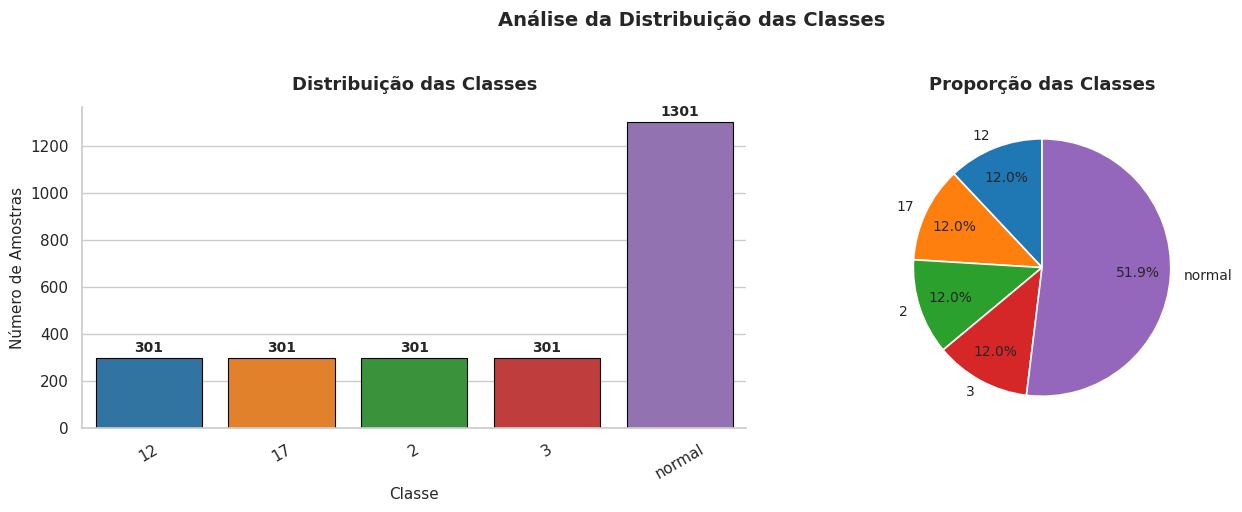

In [ ]:
import seaborn as sns

sns.set_theme(style='whitegrid', palette='tab10')
palette = sns.color_palette('tab10', n_classes)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Barplot ---
bars = sns.barplot(x=list(classes), y=list(counts),
                   hue=list(classes), palette=palette,
                   edgecolor='black', linewidth=0.8, legend=False, ax=axes[0])

axes[0].set_title('Distribuição das Classes', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Classe', fontsize=11)
axes[0].set_ylabel('Número de Amostras', fontsize=11)
axes[0].tick_params(axis='x', rotation=30)
for i, cnt in enumerate(counts):
    axes[0].text(i, cnt + n_samples * 0.005, str(cnt),
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# --- Pizza ---
wedge_props = {'linewidth': 1.2, 'edgecolor': 'white'}
axes[1].pie(counts, labels=classes, autopct='%1.1f%%',
            colors=palette, startangle=90,
            wedgeprops=wedge_props,
            textprops={'fontsize': 10},
            pctdistance=0.75)
axes[1].set_title('Proporção das Classes', fontsize=13, fontweight='bold', pad=12)

plt.suptitle('Análise da Distribuição das Classes', fontsize=14,
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# --- 6. Estatísticas descritivas dos atributos ---
df_stats = pd.DataFrame(X_all, columns=[f for f in featnames if f != 'CLASS'])
print("\n  Estatísticas descritivas (primeiros 6 atributos):")
display(df_stats.iloc[:, :6].describe().round(4))


  Estatísticas descritivas (primeiros 6 atributos):


,$c_{A0}$,$Q_{1}$,$T_{1}$,$L$,$c_{A}$,$c_{B}$
count,2505.0000,2505.0000,2505.0000,2505.0000,2505.0000,2505.0000
mean,20.0061,0.2382,30.0004,1.9982,2.7263,17.2238
std,0.1442,0.0324,0.1469,0.0255,0.3288,0.3547
min,19.5280,0.1449,29.5610,1.7098,1.7528,16.6270
25%,19.9080,0.2482,29.9070,1.9921,2.8248,17.0250
50%,20.0110,0.2498,30.0030,1.9998,2.8436,17.1220
75%,20.1010,0.2513,30.0950,2.0071,2.8587,17.2510
max,20.4520,0.2563,30.3920,2.1074,2.9102,18.4870


## **Pré-processamento dos dados**

Os algoritmos de aprendizado de máquina exigem que os dados sejam numéricos, estejam em escalas compatíveis e possuam uma separação clara entre entrada e saída. Para atender a esses requisitos, o pipeline é estruturado em duas etapas principais:

### 1. Pré-processamento dos Dados
* **Separação**: A base é dividida em **X** (as 18 variáveis de entrada do processo) e **y** (o rótulo da condição operacional).
* **Codificação**: Rótulos categóricos (`'normal'`, `'2'`, `'3'`, `'12'`, `'17'`) são convertidos para inteiros (0 a 4) via mapeamento direto, permitindo o cálculo de gradientes e métricas.
* **Padronização**: Os atributos de entrada são normalizados com `StandardScaler` (média 0 e desvio padrão 1). O ajuste (*fit*) é feito **apenas no conjunto de treino** para evitar o vazamento de informação (*data leakage*).

### 2. Divisão da Base de Dados
A separação em treino, validação e teste é feita de forma **estratificada**, garantindo a mesma proporção de classes em cada subconjunto:

| Subconjunto | Proporção | Amostras |
| :--- | :---: | :---: |
| **Treino** | 60% | ~1503 |
| **Validação** | 20% | ~501 |
| **Teste** | 20% | ~501 |

In [ ]:
# Codifica rótulos como inteiros
classes = np.unique(y_all)
class2idx = {c: i for i, c in enumerate(classes)}
idx2class = {i: c for c, i in class2idx.items()}
y_num = np.array([class2idx[c] for c in y_all])
n_classes = len(classes)

# Divisão: 60% treino, 20% validação, 20% teste (estratificada)
X_tv, X_test, y_tv, y_test = train_test_split(
    X_all, y_num, test_size=0.20, random_state=42, stratify=y_num)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv,  y_tv,  test_size=0.25, random_state=42, stratify=y_tv)

# Normalização (fit apenas no treino)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

print(f'Treino: {X_train.shape}  Validação: {X_val.shape}  Teste: {X_test.shape}')

Treino: (1503, 18)  Validação: (501, 18)  Teste: (501, 18)


## Modelo Linear com Descida de Gradiente (Softmax Regression)

O classificador adotado é a **regressão softmax** (também chamada de regressão logística multinomial), que é um modelo linear para problemas de classificação com múltiplas classes. Para cada amostra $\mathbf{x} \in \mathbb{R}^{18}$, o modelo computa um vetor de scores lineares e os converte em probabilidades via função softmax:

$$\hat{P}(y = k \mid \mathbf{x}) = \frac{e^{\mathbf{x}^\top \mathbf{w}_k + b_k}}{\sum_{j=1}^{K} e^{\mathbf{x}^\top \mathbf{w}_j + b_j}}$$

onde $K = 5$ é o número de classes, $W \in \mathbb{R}^{18 \times 5}$ é a matriz de pesos e $\mathbf{b} \in \mathbb{R}^5$ é o viés.

**Função de perda** — a otimização minimiza a entropia cruzada com regularização L2:

$$\mathcal{L}(W, \mathbf{b}) = -\frac{1}{n}\sum_{i=1}^{n} \sum_{k=1}^{K} y_{ik} \log \hat{P}_{ik} + \frac{\lambda}{2}\|W\|_F^2$$

**Gradientes** — derivando em relação a $W$ e $\mathbf{b}$:

$$\nabla_W \mathcal{L} = \frac{1}{n} X^\top (\hat{P} - Y) + \lambda W \qquad \nabla_{\mathbf{b}} \mathcal{L} = \frac{1}{n}\sum_{i}(\hat{P}_i - Y_i)$$

**Treinamento** — os parâmetros são atualizados a cada mini-batch pelo algoritmo de descida de gradiente estocástico (SGD):

$$W \leftarrow W - \eta \nabla_W \mathcal{L}, \qquad \mathbf{b} \leftarrow \mathbf{b} - \eta \nabla_{\mathbf{b}} \mathcal{L}$$

Os hiperparâmetros utilizados foram:

| Hiperparâmetro | Valor |
|---|---|
| Taxa de aprendizado $\eta$ | 0,1 |
| Épocas | 200 |
| Tamanho do mini-batch | 256 |
| Regularização L2 $\lambda$ | $10^{-4}$ |

A cada época, a perda e a acurácia são registradas nos conjuntos de treino e validação, permitindo monitorar a convergência e detectar overfitting.

In [ ]:
def softmax(Z):
    Z_shifted = Z - Z.max(axis=1, keepdims=True)  # estabilidade numérica
    eZ = np.exp(Z_shifted)
    return eZ / eZ.sum(axis=1, keepdims=True)

def cross_entropy_loss(P, y_true, n_classes):
    n = len(y_true)
    Y = np.eye(n_classes)[y_true]  # one-hot
    return -np.mean(np.sum(Y * np.log(P + 1e-15), axis=1))

def predict(X, W, b):
    return softmax(X @ W + b)

def accuracy(X, W, b, y_true):
    P = predict(X, W, b)
    return np.mean(P.argmax(axis=1) == y_true)


# Inicialização
np.random.seed(42)
n_features = X_train.shape[1]
W = np.random.randn(n_features, n_classes) * 0.01
b = np.zeros(n_classes)

# Hiperparâmetros
lr         = 0.1    # taxa de aprendizado
epochs     = 200
batch_size = 256
lambda_l2  = 1e-4   # regularização L2

train_losses, val_losses = [], []
train_accs,   val_accs   = [], []

n_train = X_train.shape[0]

for epoch in range(1, epochs + 1):
    # Embaralha mini-batches
    perm = np.random.permutation(n_train)
    X_shuf, y_shuf = X_train[perm], y_train[perm]

    for start in range(0, n_train, batch_size):
        Xb = X_shuf[start:start+batch_size]
        yb = y_shuf[start:start+batch_size]
        nb = len(yb)

        P = predict(Xb, W, b)
        Y = np.eye(n_classes)[yb]

        # Gradientes
        dL = (P - Y) / nb
        dW = Xb.T @ dL + lambda_l2 * W
        db = dL.sum(axis=0)

        W -= lr * dW
        b -= lr * db

    # Métricas por epoch
    P_tr = predict(X_train, W, b)
    P_vl = predict(X_val,   W, b)
    tl = cross_entropy_loss(P_tr, y_train, n_classes)
    vl = cross_entropy_loss(P_vl, y_val,   n_classes)
    train_losses.append(tl)
    val_losses.append(vl)
    train_accs.append(accuracy(X_train, W, b, y_train))
    val_accs.append(accuracy(X_val,   W, b, y_val))

    if epoch % 20 == 0:
        print(f'Epoch {epoch:3d}  loss_treino={tl:.4f}  loss_val={vl:.4f}  '
              f'acc_treino={train_accs[-1]:.3f}  acc_val={val_accs[-1]:.3f}')

Epoch  20  loss_treino=0.3909  loss_val=0.4029  acc_treino=0.877  acc_val=0.876
Epoch  40  loss_treino=0.3483  loss_val=0.3619  acc_treino=0.878  acc_val=0.876
Epoch  60  loss_treino=0.3321  loss_val=0.3468  acc_treino=0.878  acc_val=0.876
Epoch  80  loss_treino=0.3231  loss_val=0.3389  acc_treino=0.878  acc_val=0.876
Epoch 100  loss_treino=0.3171  loss_val=0.3336  acc_treino=0.878  acc_val=0.876
Epoch 120  loss_treino=0.3126  loss_val=0.3298  acc_treino=0.878  acc_val=0.876
Epoch 140  loss_treino=0.3091  loss_val=0.3272  acc_treino=0.878  acc_val=0.876
Epoch 160  loss_treino=0.3061  loss_val=0.3250  acc_treino=0.878  acc_val=0.876
Epoch 180  loss_treino=0.3036  loss_val=0.3231  acc_treino=0.878  acc_val=0.876
Epoch 200  loss_treino=0.3014  loss_val=0.3214  acc_treino=0.878  acc_val=0.876


## Evolução da Perda

Os gráficos abaixo mostram a evolução da **entropia cruzada** e da **acurácia** ao longo das 200 épocas de treinamento, registradas separadamente nos conjuntos de treino e validação.

A curva de perda permite verificar:

* **convergência** — se a perda diminui de forma estável ao longo das épocas;
* **overfitting** — se a perda de treino continua caindo enquanto a de validação estagna ou aumenta;
* **underfitting** — se ambas as curvas permanecem altas mesmo ao final do treinamento.

A curva de acurácia complementa essa análise ao mostrar o desempenho de classificação diretamente interpretável. O comportamento próximo entre as curvas de treino e validação indica boa capacidade de generalização do modelo linear para este problema.

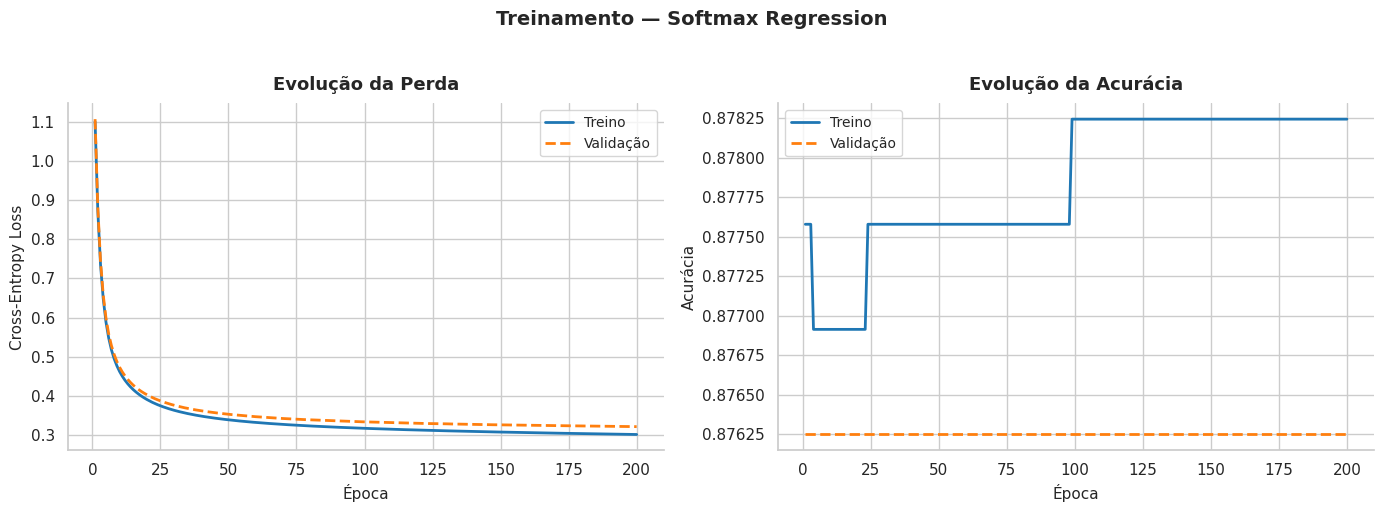

In [ ]:
sns.set_theme(style='whitegrid', palette='tab10')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(train_losses) + 1)

# --- Perda ---
sns.lineplot(x=epochs_range, y=train_losses, label='Treino',   ax=axes[0], linewidth=2)
sns.lineplot(x=epochs_range, y=val_losses,   label='Validação', ax=axes[0], linewidth=2, linestyle='--')
axes[0].set_title('Evolução da Perda', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Época', fontsize=11)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# --- Acurácia ---
sns.lineplot(x=epochs_range, y=train_accs, label='Treino',    ax=axes[1], linewidth=2)
sns.lineplot(x=epochs_range, y=val_accs,   label='Validação', ax=axes[1], linewidth=2, linestyle='--')
axes[1].set_title('Evolução da Acurácia', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Época', fontsize=11)
axes[1].set_ylabel('Acurácia', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Treinamento — Softmax Regression', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Avaliação no Conjunto de Teste

Após o treinamento, o modelo é avaliado no conjunto de teste — dados que não participaram nem do treinamento nem da seleção de hiperparâmetros — fornecendo uma estimativa imparcial do desempenho de generalização.

O relatório apresenta, por classe, as métricas de **precisão**, **sensibilidade (recall)** e **F1-score**, além da acurácia global. Destaca-se que o modelo obteve desempenho elevado para as falhas 2, 3 e 12, mas **não detectou nenhuma amostra da falha 17**, com precisão e recall nulos — indicando que as variáveis medidas disponíveis não separam linearmente essa condição das demais. Esse resultado justifica a análise da matriz de confusão na etapa seguinte.


In [ ]:
P_test = predict(X_test, W, b)
y_pred = P_test.argmax(axis=1)
target_names = [idx2class[i] for i in range(n_classes)]

print("=== Relatório de Classificação ===")
print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))

=== Relatório de Classificação ===
              precision    recall  f1-score   support

          12       1.00      0.97      0.98        60
          17       0.00      0.00      0.00        60
           2       1.00      0.98      0.99        60
           3       1.00      0.98      0.99        60
      normal       0.80      1.00      0.89       261

    accuracy                           0.87       501
   macro avg       0.76      0.79      0.77       501
weighted avg       0.78      0.87      0.82       501



## Matriz de Confusão (Treino, Validação e Teste)

A matriz de confusão exibe, para cada classe real (linhas), como as amostras foram distribuídas entre as classes preditas (colunas). A diagonal principal representa as classificações corretas; os elementos fora da diagonal indicam os erros cometidos pelo modelo.

As matrizes são geradas para os três subconjuntos, permitindo comparar o comportamento do modelo em diferentes regimes:

* **Treino** — mostra o ajuste do modelo aos dados de otimização; erros elevados aqui indicam underfitting;
* **Validação** — usada durante o treinamento para monitorar generalização; divergência em relação ao treino indica overfitting;
* **Teste** — avaliação final e imparcial; reflete o desempenho esperado em operação real.

Os principais padrões observados são:
* as falhas 2, 3 e 12 são classificadas com alta acurácia nos três subconjuntos;
* a falha 17 é sistematicamente confundida com a classe `normal`, confirmando a limitação do modelo linear em separar essa condição — suas amostras provavelmente se sobrepõem à região de operação normal no espaço de atributos;
* a classe `normal`, por ser majoritária, tende a absorver as amostras mal classificadas das demais classes.

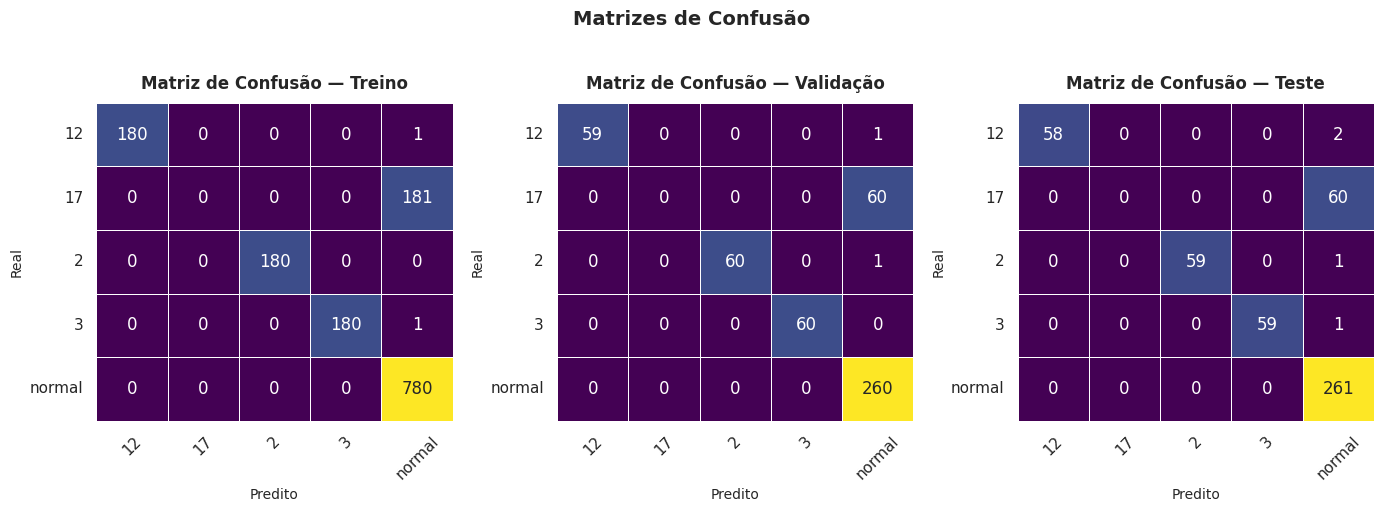

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, (split_name, X_s, y_s) in zip(axes, [
        ('Treino',    X_train, y_train),
        ('Validação', X_val,   y_val),
        ('Teste',     X_test,  y_test)]):
    y_pred_s = predict(X_s, W, b).argmax(axis=1)
    cm = confusion_matrix(y_s, y_pred_s)
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis',
                xticklabels=target_names, yticklabels=target_names,
                linewidths=0.5, linecolor='white',
                cbar=False, ax=ax)
    ax.set_title(f'Matriz de Confusão — {split_name}', fontsize=12,
                 fontweight='bold', pad=10)
    ax.set_xlabel('Predito', fontsize=10)
    ax.set_ylabel('Real', fontsize=10)
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.suptitle('Matrizes de Confusão', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Critérios de Desempenho

Para quantificar o desempenho do classificador, são calculadas as seguintes métricas para cada subconjunto (treino, validação e teste):

**Acurácia** — proporção de amostras classificadas corretamente:

$$\text{Acurácia} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TP} + \text{FP} + \text{FN}}$$

**Precisão** — dos exemplos classificados como uma classe, quantos realmente pertencem a ela:

$$\text{Precisão} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$

**Sensibilidade (Recall)** — dos exemplos que realmente pertencem a uma classe, quantos foram corretamente identificados:

$$\text{Sensibilidade} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

**F1-score** — média harmônica entre precisão e sensibilidade, mais informativa que a acurácia em bases desbalanceadas:

$$\text{F1} = 2 \cdot \frac{\text{Precisão} \times \text{Sensibilidade}}{\text{Precisão} + \text{Sensibilidade}}$$

Todas as métricas são calculadas com ponderação pelo suporte de cada classe (`average='weighted'`), o que é mais adequado dado o desbalanceamento observado na base. A falha 17 recebe métricas nulas por não ser detectada pelo modelo linear, o que puxa o desempenho médio para baixo — em especial o F1 macro — sinalizando a necessidade de um classificador não-linear para esse cenário.

In [ ]:
def metrics_table(y_true, y_pred, split_name):
    acc  = accuracy_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    print(f'\n--- {split_name} ---')
    print(f'  Acurácia              : {acc:.4f}')
    print(f'  Precisão              : {prec:.4f}')
    print(f'  Sensibilidade (Recall): {rec:.4f}')
    print(f'  F1-score              : {f1:.4f}')

for split_name, X_s, y_s in [('Treino',    X_train, y_train),
                               ('Validação', X_val,   y_val),
                               ('Teste',     X_test,  y_test)]:
    y_pred_s = predict(X_s, W, b).argmax(axis=1)
    metrics_table(y_s, y_pred_s, split_name)


--- Treino ---
  Acurácia              : 0.8782
  Precisão              : 0.7810
  Sensibilidade (Recall): 0.8782
  F1-score              : 0.8244

--- Validação ---
  Acurácia              : 0.8762
  Precisão              : 0.7803
  Sensibilidade (Recall): 0.8762
  F1-score              : 0.8229

--- Teste ---
  Acurácia              : 0.8723
  Precisão              : 0.7777
  Sensibilidade (Recall): 0.8723
  F1-score              : 0.8193
